# 03 · Data Preprocessing and Cleaning

**Artemis-X - AI perception for lunar rock and obstacle detection**

**Objective.** Explain the S2-H cleaning pipeline that produced curated-dataset-v1.1, and quantify its effect without re-running it (Tasks C, C v1.1, D.2).

**Research questions**

1. How does the pipeline turn raw mask components into VALID / REVIEW / REJECTED boxes?
2. What changed between v1 and v1.1?
3. Were the original data preserved?

**Inputs (published, pixel-free artifacts)**

- `artifacts/data/cleaning_quality_metrics_v1.1.json`
- `artifacts/data/threshold_study.json`
- `artifacts/provenance/VERSIONS.json`

> **Provisional results.** All labels were produced by an automated pipeline (S2-H policy) and have **not** been verified by humans. Metrics are measured on synthetic renders only and do not establish performance on real lunar imagery or readiness for rover deployment.

## Setup
The notebook imports the `artemis_x` package from `src/` and reads only published artifacts. It never trains a model, rebuilds a dataset or evaluates the held-out test split.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "artemis_x").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from artemis_x.config import paths
from artemis_x.reporting import artifacts as A, plots as P
P.use_style()
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)
# Dataset pixels are never committed (redistribution licence unconfirmed). Set ARTEMIS_SHOW_LOCAL_IMAGES=1 to view
# local images when the dataset folder is present.
SHOW_LOCAL_IMAGES = os.environ.get("ARTEMIS_SHOW_LOCAL_IMAGES") == "1" and paths.local_dataset_available()
FIG = paths.ARTIFACTS / "figures"
print("artemis_x ready | local dataset present:", paths.local_dataset_available(), "| showing local images:", SHOW_LOCAL_IMAGES)

artemis_x ready | local dataset present: True | showing local images: False


## 1. Pipeline (implemented in `backend/analysis/dataset_cleaning`)
```mermaid
flowchart LR
  R[render + ground mask + CSV] --> X[extract mask components]
  X --> F[size floor >= 50 px]
  F --> W[watershed split of merged blobs<br/>neck ratio 0.7]
  W --> V[visibility rule<br/>edge >= 100 or contrast >= 25]
  V --> S{status}
  S --> VA[VALID]
  S --> RE[REVIEW_REQUIRED]
  S --> RJ[REJECTED]
  C[CSV large-rock boxes] --> VA
```
The rules are deterministic, and every decision is recorded with its reason (`cleaning_decisions.csv`, local-only).

In [2]:
q = A.load_json("data/cleaning_quality_metrics_v1.1.json")["automated_full_dataset"]
pd.Series(q["status_counts"]).rename("boxes").to_frame().assign(share=lambda x: x["boxes"] / x["boxes"].sum())

,boxes,share
REJECTED,50005,0.099
REVIEW_REQUIRED,192784,0.382
VALID,261239,0.518


In [3]:
sbs = pd.Series(q["status_by_source"])
sbs.index = pd.MultiIndex.from_tuples([tuple(k.split("|")) for k in sbs.index], names=["source", "status"])
sbs.unstack(fill_value=0)[["VALID", "REVIEW_REQUIRED", "REJECTED"]]

status,VALID,REVIEW_REQUIRED,REJECTED
source,,,
csv_large,17518,167,0
mask_blue,21952,10663,17757
mask_blue_split,2140,534,203
mask_green,182735,165565,31000
mask_green_split,36894,15855,1045


## 2. Effect on box sizes (raw S2 components vs cleaned VALID)

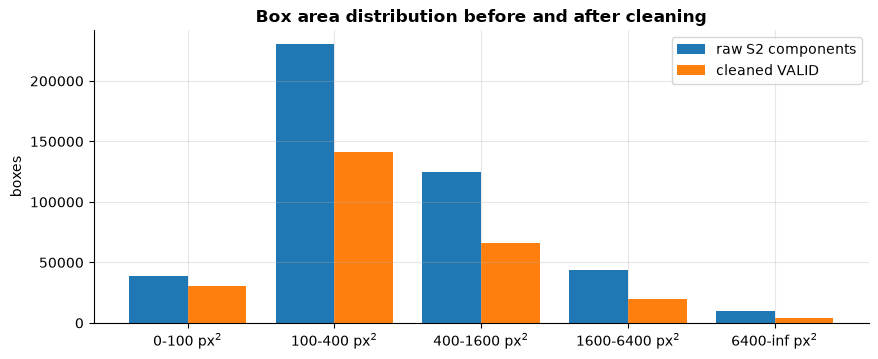

In [4]:
import numpy as np, matplotlib.pyplot as plt
bins = ["0-100", "100-400", "400-1600", "1600-6400", "6400-inf"]
raw = [q["box_sizes"]["raw_s2"]["area_bins"][b] for b in bins]; val = [q["box_sizes"]["cleaned_valid"]["area_bins"][b] for b in bins]
x = np.arange(len(bins)); fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(x - .2, raw, .4, label="raw S2 components"); ax.bar(x + .2, val, .4, label="cleaned VALID")
ax.set_xticks(x); ax.set_xticklabels([b + " px$^2$" for b in bins]); ax.set_ylabel("boxes"); ax.set_title("Box area distribution before and after cleaning")
ax.legend(); plt.show()

## 3. Version history
`curated-dataset-v1.1` fixed one defect found in Task D: rule **D05** (duplicate CSV and mask boxes) had not been applied to
watershed-split pieces. The change is small and fully registered by content hash.

In [5]:
c = A.curated_counts().set_index("version")[["VALID", "REVIEW_REQUIRED", "REJECTED"]]
c.loc["change v1 -> v1.1"] = c.iloc[1] - c.iloc[0]; c

,VALID,REVIEW_REQUIRED,REJECTED
version,,,
curated-dataset-v1,261385,192826,49817
curated-dataset-v1.1,261239,192784,50005
change v1 -> v1.1,-146,-42,188


## 4. Calibration of the size floor (Task D.2 threshold study)
Lowering the 50 px floor would add many tiny, mostly invisible components.

In [6]:
t = A.load_json("data/threshold_study.json")
pd.DataFrame(t["table"]).T[["per_image", "median_box_side_px", "visible_by_proxy_rate", "min_side_lt_6px_rate", "low_solidity_merge_risk_rate"]]

,per_image,median_box_side_px,visible_by_proxy_rate,min_side_lt_6px_rate,low_solidity_merge_risk_rate
tol127_min10,99.02,6.0,0.531,0.423,0.048
tol127_min15,84.19,7.0,0.556,0.323,0.057
tol127_min20,74.27,8.0,0.575,0.239,0.064
tol127_min25,66.95,9.0,0.589,0.173,0.071
tol127_min30,61.27,10.0,0.600,0.124,0.077
tol127_min40,52.84,11.0,0.615,0.060,0.088
tol127_min50,46.74,12.0,0.624,0.028,0.096
tol80_min10,113.24,6.0,0.438,0.425,0.055
tol80_min15,95.65,7.0,0.465,0.320,0.065
tol80_min20,84.08,8.0,0.485,0.234,0.073


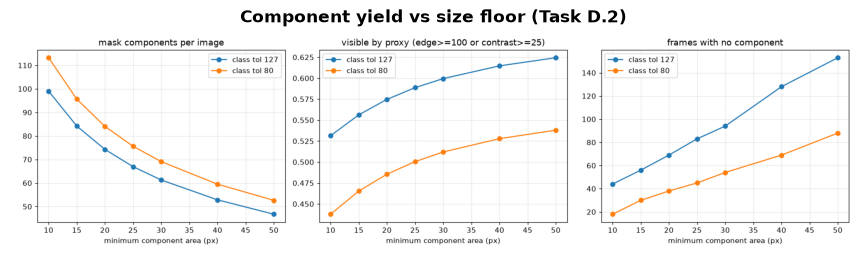

In [7]:
P.show_png(FIG / "d2_threshold_curves.png", "Component yield vs size floor (Task D.2)")

## 5. Source preservation
The source dataset fingerprint was recorded before and after cleaning:

In [8]:
i = A.load_json("data/cleaning_quality_metrics_v1.1.json")["integrity"]
pd.Series({"files": i["source_fingerprint_before"]["files"], "bytes": i["source_fingerprint_before"]["bytes"],
           "sha256 before": i["source_fingerprint_before"]["sha256"][:16] + "...", "sha256 after": i["source_fingerprint_after"]["sha256"][:16] + "...",
           "unchanged": i["unchanged"]}).to_frame("source dataset fingerprint")

,source dataset fingerprint
files,38590
bytes,17332610398
sha256 before,fecca0cf45c9a9c0...
sha256 after,fecca0cf45c9a9c0...
unchanged,True


## Provenance
Each artifact below is a verified copy (or path-sanitised derivative) of a historical experiment output; `scripts/verify_artifacts.py` re-checks every hash.

In [9]:
A.provenance(['data/cleaning_quality_metrics_v1.1.json', 'data/threshold_study.json', 'figures/d2_threshold_curves.png'])

,artifact,mode,source (local experiments/),sha256
0,artifacts/data/cleaning_quality_metrics_v1.1.json,COPY,experiments/dataset-cleaning-v1.1/quality_metrics.json,a14fff2a8a9091be...
1,artifacts/data/threshold_study.json,COPY,experiments/remediation/threshold_study/threshold_study.json,1cc25b12a0ebf46e...
2,artifacts/figures/d2_threshold_curves.png,COPY,experiments/remediation/threshold_study/threshold_curves.png,b144283bf79654ba...


## Conclusion
- Cleaning is rule-based, deterministic and fully logged. Original images and annotations were never modified.
- About 52% of candidate boxes are VALID and 38% go to REVIEW. Such a large uncertain share is itself a finding: **label noise is the
  main scientific risk** of this project.
- The 50 px floor is a calibrated compromise. Rocks below it are out of scope and are ignored, not penalised, at evaluation
  time.

**Next:** [04_yolo_dataset_preparation.ipynb](04_yolo_dataset_preparation.ipynb)